In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/retail_store_sales_cleaned.csv')

In [5]:
print("Dataset dimensions:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset dimensions: (11382, 11)

First five records:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11382 entries, 0 to 11381
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    11382 non-null  object 
 1   Customer ID       11382 non-null  object 
 2   Category          11382 non-null  object 
 3   Item              10285 non-null  object 
 4   Price Per Unit    11381 non-null  float64
 5   Quantity          10838 non-null  float64
 6   Total Spent       10838 non-null  float64
 7   Payment Method    11381 non-null  object 
 8   Location          11381 non-null  object 
 9   Transaction Date  11381 non-null  object 
 10  Discount Applied  7594 non-null   object 
dtypes: float64(3), object(8)
memory usage: 978.3+ KB


In [6]:
# Convert Transaction Date to datetime
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

# Convert Discount Applied to nullable Boolean
df["Discount Applied"] = df["Discount Applied"].astype("boolean")

# Convert Quantity to nullable integer
df["Quantity"] = df["Quantity"].astype("Int64")

# Verify data types
print(df.dtypes)

Transaction ID              object
Customer ID                 object
Category                    object
Item                        object
Price Per Unit             float64
Quantity                     Int64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied           boolean
dtype: object


In [7]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (11382, 11)

Missing values:
Transaction ID         0
Customer ID            0
Category               0
Item                1097
Price Per Unit         1
Quantity             544
Total Spent          544
Payment Method         1
Location               1
Transaction Date       1
Discount Applied    3788
dtype: int64

Duplicate records: 0


In [8]:
numerical_summary = df[
    ["Price Per Unit", "Quantity", "Total Spent"]
].describe()

display(numerical_summary)

,Price Per Unit,Quantity,Total Spent
count,11381.000000,10838.0,10838.000000
mean,23.370618,5.538107,129.684997
std,10.732143,2.859926,94.628786
min,5.000000,1.0,5.000000
25%,14.000000,3.0,52.000000
50%,23.000000,6.0,108.500000
75%,33.500000,8.0,192.000000
max,41.000000,10.0,410.000000


In [9]:
total_revenue = df["Total Spent"].sum()
average_transaction_value = df["Total Spent"].mean()
median_transaction_value = df["Total Spent"].median()
average_quantity = df["Quantity"].mean()
average_unit_price = df["Price Per Unit"].mean()

print("Total recorded revenue:", round(total_revenue, 2))
print("Average transaction value:", round(average_transaction_value, 2))
print("Median transaction value:", round(median_transaction_value, 2))
print("Average purchase quantity:", round(average_quantity, 2))
print("Average unit price:", round(average_unit_price, 2))

Total recorded revenue: 1405526.0
Average transaction value: 129.68
Median transaction value: 108.5
Average purchase quantity: 5.54
Average unit price: 23.37


In [10]:
category_analysis = (
    df.groupby("Category")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Transaction_Count=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

display(category_analysis.round(2))

,Total_Revenue,Total_Quantity,Transaction_Count,Average_Transaction_Value
Category,,,,
Butchers,191469.5,7519,1433,139.86
Electric household essentials,181864.0,7385,1414,134.51
Beverages,177989.5,7565,1418,131.65
Food,177356.5,7655,1447,128.89
Furniture,176880.5,7675,1446,127.71
Computers and electric accessories,173903.5,7538,1423,129.30
Milk Products,163414.5,7560,1430,119.54
Patisserie,162648.0,7125,1370,125.89
C,0.0,0,1,NaN


In [11]:
category_analysis["Revenue_Share_%"] = (
    category_analysis["Total_Revenue"] /
    category_analysis["Total_Revenue"].sum()
) * 100

display(category_analysis.round(2))

,Total_Revenue,Total_Quantity,Transaction_Count,Average_Transaction_Value,Revenue_Share_%
Category,,,,,
Butchers,191469.5,7519,1433,139.86,13.62
Electric household essentials,181864.0,7385,1414,134.51,12.94
Beverages,177989.5,7565,1418,131.65,12.66
Food,177356.5,7655,1447,128.89,12.62
Furniture,176880.5,7675,1446,127.71,12.58
Computers and electric accessories,173903.5,7538,1423,129.30,12.37
Milk Products,163414.5,7560,1430,119.54,11.63
Patisserie,162648.0,7125,1370,125.89,11.57
C,0.0,0,1,NaN,0.00


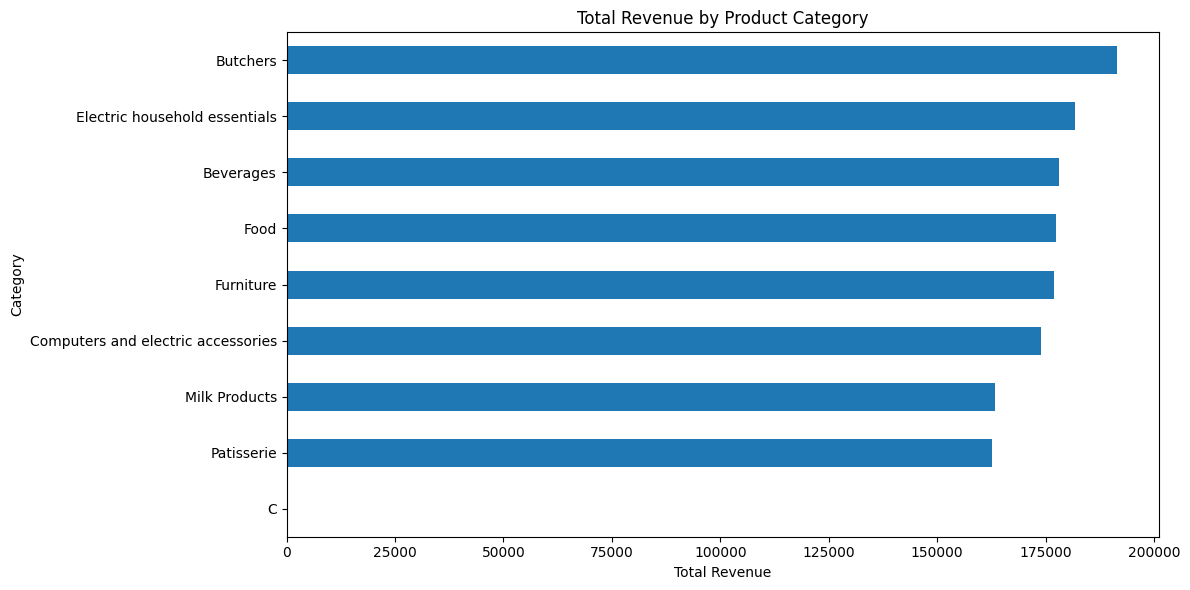

In [12]:
plt.figure(figsize=(12, 6))

category_analysis["Total_Revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [13]:
print("Number of categories:", len(category_analysis))
print("Category names:", category_analysis.index.tolist())
print("\nMissing revenue values:")
print(category_analysis["Total_Revenue"].isna().sum())

Number of categories: 9
Category names: ['Butchers', 'Electric household essentials', 'Beverages', 'Food', 'Furniture', 'Computers and electric accessories', 'Milk Products', 'Patisserie', 'C']

Missing revenue values:
0


In [14]:
monthly_sales = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

display(monthly_sales)

,Total Spent
Transaction Date,
2022-01,50435.5
2022-02,38777.0
2022-03,37916.5
2022-04,36363.0
2022-05,35578.5
2022-06,38695.5
2022-07,40221.5
2022-08,37552.0
2022-09,42027.5


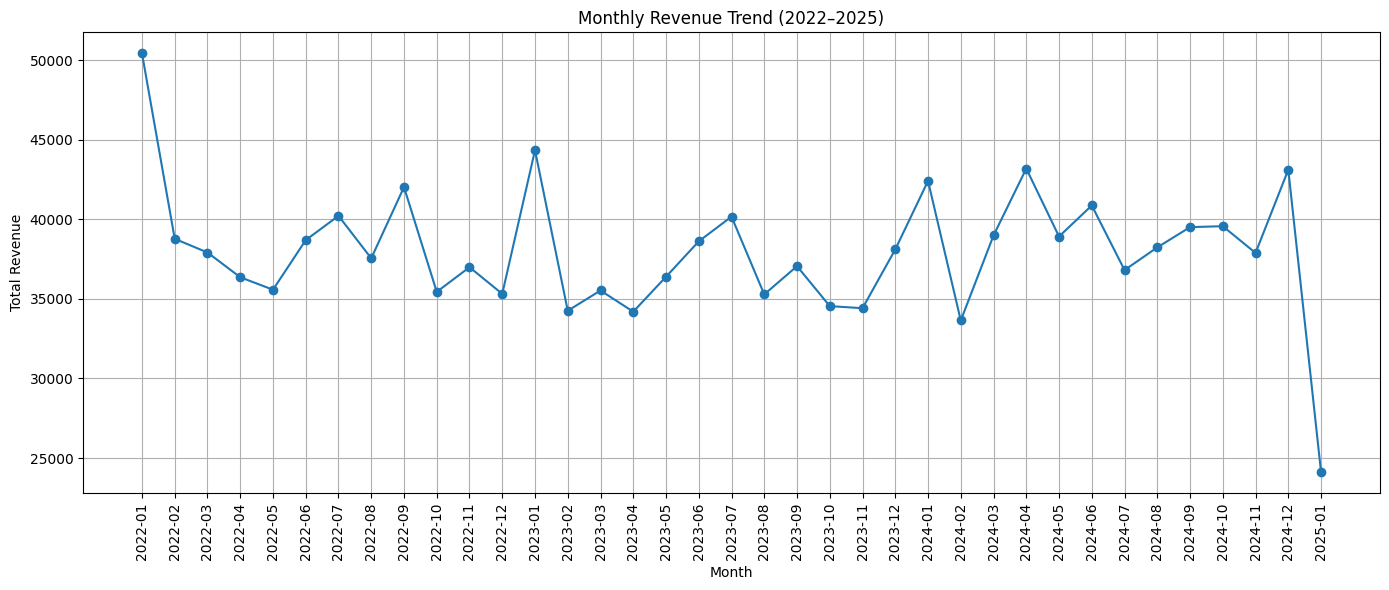

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
payment_analysis = df["Payment Method"].value_counts()

display(payment_analysis)

,count
Payment Method,
Cash,3908
Digital Wallet,3761
Credit Card,3712


In [17]:
print("Total rows:", len(df))

print("\nPayment method counts including missing values:")
print(df["Payment Method"].value_counts(dropna=False))

print("\nUnique payment method values:")
print(df["Payment Method"].unique())

Total rows: 11382

Payment method counts including missing values:
Payment Method
Cash              3908
Digital Wallet    3761
Credit Card       3712
NaN                  1
Name: count, dtype: int64

Unique payment method values:
['Digital Wallet' 'Credit Card' 'Cash' nan]


In [18]:
df_check = pd.read_csv('/content/retail_store_sales_cleaned.csv')

print("Current DataFrame:", df.shape)
print("Original cleaned CSV:", df_check.shape)

print("\nOriginal payment method counts:")
print(df_check["Payment Method"].value_counts(dropna=False))

Current DataFrame: (11382, 11)
Original cleaned CSV: (12575, 11)

Original payment method counts:
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64


In [20]:
df = df_check.copy()

df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"], errors="coerce"
)

df["Discount Applied"] = df["Discount Applied"].astype("boolean")
df["Quantity"] = df["Quantity"].astype("Int64")

print("Restored dataset shape:", df.shape)
print("\nPayment method distribution:")
print(df["Payment Method"].value_counts(dropna=False))

Restored dataset shape: (12575, 11)

Payment method distribution:
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64


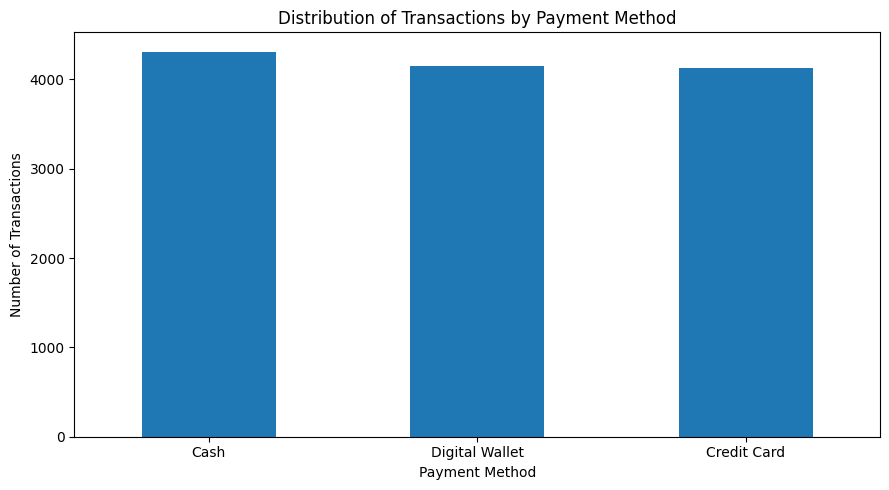

In [21]:
plt.figure(figsize=(9, 5))

payment_analysis = df["Payment Method"].value_counts()

payment_analysis.plot(kind="bar")

plt.title("Distribution of Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
location_analysis = (
    df.groupby("Location")
    .agg(
        Transaction_Count=("Transaction ID", "count"),
        Total_Revenue=("Total Spent", "sum"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
)

location_analysis["Revenue_Share_%"] = (
    location_analysis["Total_Revenue"] /
    location_analysis["Total_Revenue"].sum()
) * 100

display(location_analysis.round(2))

,Transaction_Count,Total_Revenue,Average_Transaction_Value,Revenue_Share_%
Location,,,,
In-store,6221,760670.0,128.86,49.01
Online,6354,791401.0,130.42,50.99


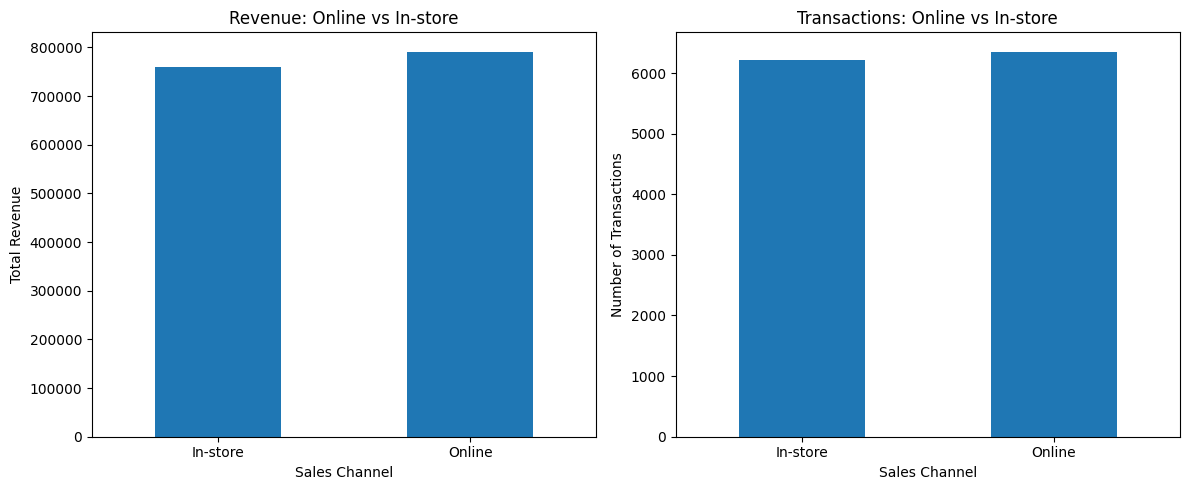

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Revenue comparison
location_analysis["Total_Revenue"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Revenue: Online vs In-store")
axes[0].set_xlabel("Sales Channel")
axes[0].set_ylabel("Total Revenue")
axes[0].tick_params(axis="x", rotation=0)

# Transaction comparison
location_analysis["Transaction_Count"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Transactions: Online vs In-store")
axes[1].set_xlabel("Sales Channel")
axes[1].set_ylabel("Number of Transactions")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [24]:
discount_analysis = (
    df["Discount Applied"]
    .value_counts(dropna=True)
    .rename(index={True: "Discount Applied",
                   False: "No Discount"})
)

display(discount_analysis)

,count
Discount Applied,
Discount Applied,4219
No Discount,4157


In [25]:
discount_comparison = (
    df.groupby("Discount Applied", dropna=True)
    .agg(
        Transaction_Count=("Transaction ID", "count"),
        Total_Revenue=("Total Spent", "sum"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
)

discount_comparison.index = discount_comparison.index.map(
    {True: "Discount Applied", False: "No Discount"}
)

display(discount_comparison.round(2))

,Transaction_Count,Total_Revenue,Average_Transaction_Value
Discount Applied,,,
No Discount,4157,515135.0,129.95
Discount Applied,4219,524443.5,130.49


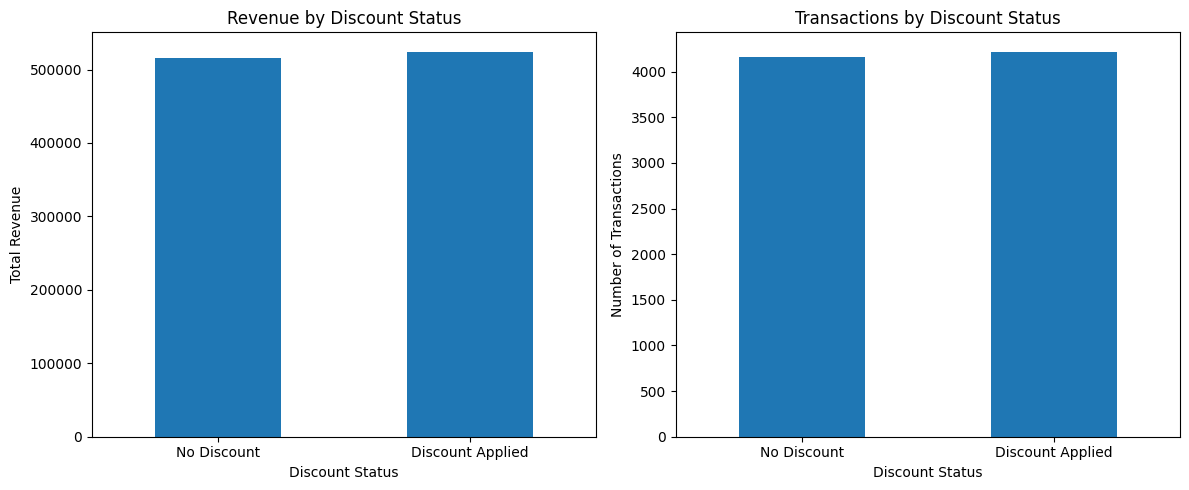

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Revenue comparison
discount_comparison["Total_Revenue"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Revenue by Discount Status")
axes[0].set_xlabel("Discount Status")
axes[0].set_ylabel("Total Revenue")
axes[0].tick_params(axis="x", rotation=0)

# Transaction comparison
discount_comparison["Transaction_Count"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Transactions by Discount Status")
axes[1].set_xlabel("Discount Status")
axes[1].set_ylabel("Number of Transactions")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [27]:
print("Dataset shape:", df.shape)
print("Total recorded revenue:", df["Total Spent"].sum())
print("Missing Total Spent:", df["Total Spent"].isna().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nCategory transaction counts:")
print(df["Category"].value_counts().sort_index())

print("\nPayment method counts:")
print(df["Payment Method"].value_counts(dropna=False))

print("\nLocation transaction counts:")
print(df["Location"].value_counts())

print("\nDiscount status counts:")
print(df["Discount Applied"].value_counts(dropna=False))

Dataset shape: (12575, 11)
Total recorded revenue: 1552071.0
Missing Total Spent: 604
Duplicate records: 0

Category transaction counts:
Category
Beverages                             1567
Butchers                              1568
Computers and electric accessories    1558
Electric household essentials         1591
Food                                  1588
Furniture                             1591
Milk Products                         1584
Patisserie                            1528
Name: count, dtype: int64

Payment method counts:
Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64

Location transaction counts:
Location
Online      6354
In-store    6221
Name: count, dtype: int64

Discount status counts:
Discount Applied
True     4219
<NA>     4199
False    4157
Name: count, dtype: Int64
